# EcoSort AI — Milestone 1 baseline

This notebook **loads and inspects** a waste-image dataset. It does **not** train a model.

Expected folder layout (class names = folder names):

```text
data/raw/
  plastic/
    image1.jpg
  paper/
    image2.jpg
  organic/
    image3.jpg
```

Run this notebook from `notebooks/` (the default when you open it in Jupyter) so the relative path `../data/raw` is correct.

In [8]:
# Standard libraries we need for paths, arrays, and plots.
from pathlib import Path

import matplotlib.pyplot as plt
import tensorflow as tf

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [2]:
# --- Dataset settings (easy to change later) ---
# RAW_DATA_DIR: images grouped into one folder per waste class
# IMAGE_SIZE: every image is resized to 224x224 (common for image models)
# BATCH_SIZE: how many images are grouped together in one training step
# VALIDATION_SPLIT: 20% of images are held out to check the model later
# SEED: keeps the train/validation split the same each time you run this

RAW_DATA_DIR = Path("../data/raw")
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
VALIDATION_SPLIT = 0.2
SEED = 42

print("Looking for images in:", RAW_DATA_DIR.resolve())

Looking for images in: /Users/farrel/Documents/ecosort-ai/data/raw


In [3]:
# Stop early with a clear message if the dataset is missing or empty.
# Keras needs at least two class folders, each containing images.

if not RAW_DATA_DIR.exists():
    raise FileNotFoundError(
        f"Could not find {RAW_DATA_DIR.resolve()}. "
        "Create class folders under data/raw/ and add images."
    )

class_folders = [p for p in RAW_DATA_DIR.iterdir() if p.is_dir() and not p.name.startswith(".")]
if len(class_folders) < 2:
    raise FileNotFoundError(
        "Need at least two class folders inside data/raw/ "
        "(for example data/raw/plastic/ and data/raw/paper/)."
    )

print("Found class folders:")
for folder in sorted(class_folders):
    n_files = len([f for f in folder.iterdir() if f.is_file() and not f.name.startswith(".")])
    print(f"  - {folder.name}: {n_files} files")

Found class folders:
  - cardboard: 403 files
  - glass: 501 files
  - metal: 410 files
  - paper: 594 files
  - plastic: 482 files
  - trash: 137 files


In [4]:
# Load images with Keras. This:
#   1. reads files from each class folder
#   2. resizes them to 224x224
#   3. groups them into batches
#   4. splits them into training and validation sets
#
# Use the same seed for both calls so an image cannot appear in both splits.

train_ds = tf.keras.utils.image_dataset_from_directory(
    RAW_DATA_DIR,
    validation_split=VALIDATION_SPLIT,
    subset="training",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    RAW_DATA_DIR,
    validation_split=VALIDATION_SPLIT,
    subset="validation",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
)

Found 2527 files belonging to 6 classes.
Using 2022 files for training.
Found 2527 files belonging to 6 classes.
Using 505 files for validation.


In [5]:
# Keras stores folder names (in alphabetical order) as class labels.
print("Detected class names:", train_ds.class_names)
print("Number of classes:", len(train_ds.class_names))

Detected class names: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
Number of classes: 6


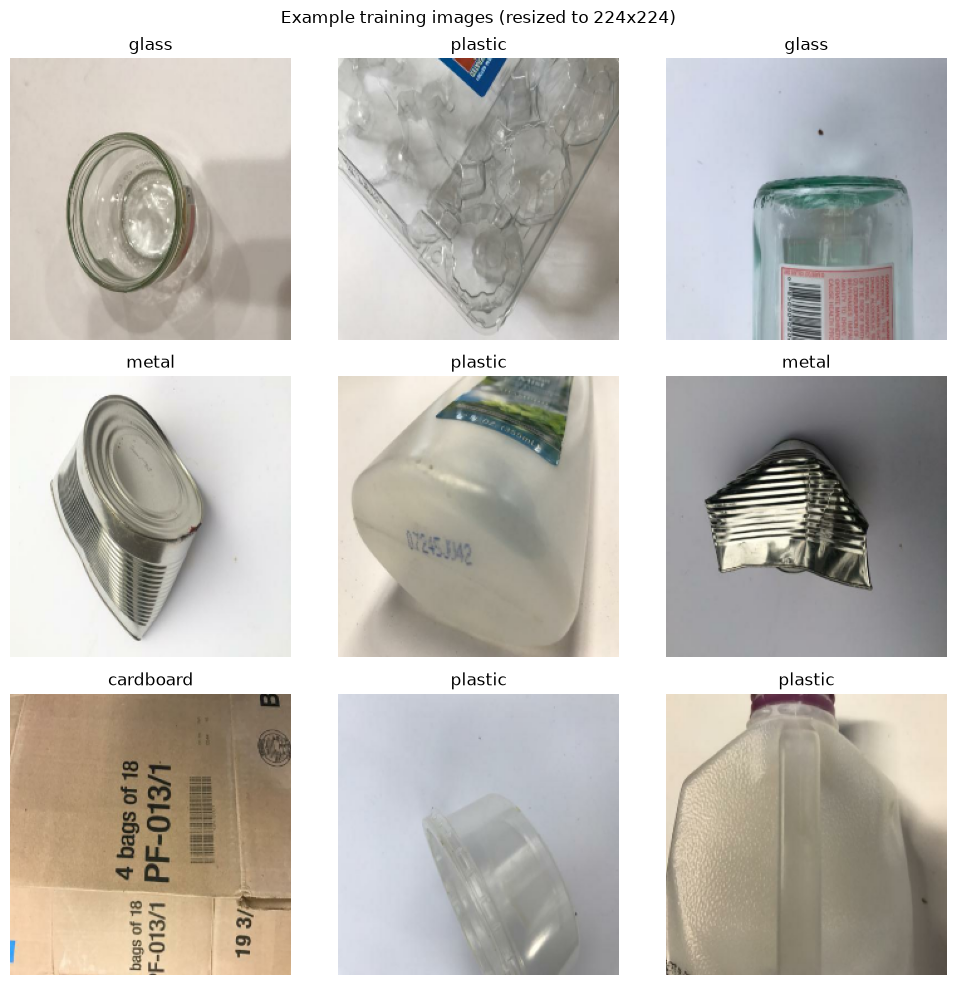

In [6]:
# Show a few training images so we can check they loaded correctly.
# Pixel values from image_dataset_from_directory are in the 0–255 range.

plt.figure(figsize=(10, 10))
for images, labels in train_ds.take(1):
    n_show = min(9, images.shape[0])
    for i in range(n_show):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(train_ds.class_names[int(labels[i])])
        plt.axis("off")
plt.suptitle("Example training images (resized to 224x224)")
plt.tight_layout()
plt.show()

In [7]:
# A "batch" is one group of BATCH_SIZE images.
# Cardinality is how many of those groups TensorFlow will iterate over.

n_train_batches = tf.data.experimental.cardinality(train_ds).numpy()
n_val_batches = tf.data.experimental.cardinality(val_ds).numpy()

print(f"Training batches:   {n_train_batches}")
print(f"Validation batches: {n_val_batches}")
print(f"Batch size:         {BATCH_SIZE}")
print()
print("Milestone 1 stops here — no model is trained in this notebook.")

Training batches:   64
Validation batches: 16
Batch size:         32

Milestone 1 stops here — no model is trained in this notebook.
